# Part 1.2: Signal versus sampling noise

The target is annual ACS severe rent burden: the percent of renter households paying half or more of income on rent.
It comes from a survey sample, so each state-year value carries sampling error, and the Census Bureau publishes a
margin of error for it. This notebook asks:

1. How much of the variation in the target is between states, between years, or left over?
2. How large is the sampling error, and which states suffer most?
3. How much of the year-to-year movement could sampling error alone produce?
4. Does a model with no dynamics at all (state and year effects plus sampling noise) reproduce what we see?

The answers set a ceiling on what any forecasting model can achieve, so they come before any model.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from viz import apply_style, SERIES, save_figure, end_label, dot, SURFACE, INK_2, MUTED, GRID

apply_style()
pd.set_option("display.width", 200)
rng = np.random.default_rng(20261006)

panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
acs = panel[panel.acs_available == 1].copy()
Z90 = 1.645  # a published ACS margin of error is a 90 percent margin: standard error = margin / 1.645
TARGET, MOE = "severe_rent_burden_pct", "severe_rent_burden_pct_moe"
acs["se"] = acs[MOE] / Z90
print(f"{len(acs)} state-years; target ranges {acs[TARGET].min():.1f} to {acs[TARGET].max():.1f} percent")

714 state-years; target ranges 15.8 to 32.6 percent


## 1. Where does the variation sit?

Variance of each series split into: differences between states (state means), differences between years common to
all states (year effects), and what is left (state-specific movement plus sampling error).

In [2]:
def decompose(col):
    y = acs.pivot(index="state_fips", columns="year", values=col)
    grand = y.stack().mean()
    total = ((y - grand) ** 2).sum().sum()
    state_part = (((y.mean(axis=1) - grand) ** 2).sum()) * y.shape[1]
    year_part = (((y.mean(axis=0) - grand) ** 2).sum()) * y.shape[0]
    resid = ((y - y.mean(axis=1).values[:, None] - y.mean(axis=0).values[None, :] + grand) ** 2).sum().sum()
    return {"between states": state_part / total, "common year effects": year_part / total, "left over": resid / total}

dec = pd.DataFrame({c: decompose(c) for c in ["severe_rent_burden_pct", "rent_burden_30_pct", "median_gross_rent"]}).T
display((dec * 100).round(1).rename_axis("share of variance, percent"))

,between states,common year effects,left over
"share of variance, percent",,,
severe_rent_burden_pct,73.5,12.0,14.4
rent_burden_30_pct,78.2,9.3,12.5
median_gross_rent,59.5,35.4,5.1


## 2. How noisy is each observation?

The margin of error of the severe burden rate uses the Census proportion formula (built in `build_panel.py`). The
chart shows it against state size for 2024: small states carry large margins.

count    714.00
mean       1.25
std        0.64
min        0.23
50%        1.07
90%        2.22
max        3.55


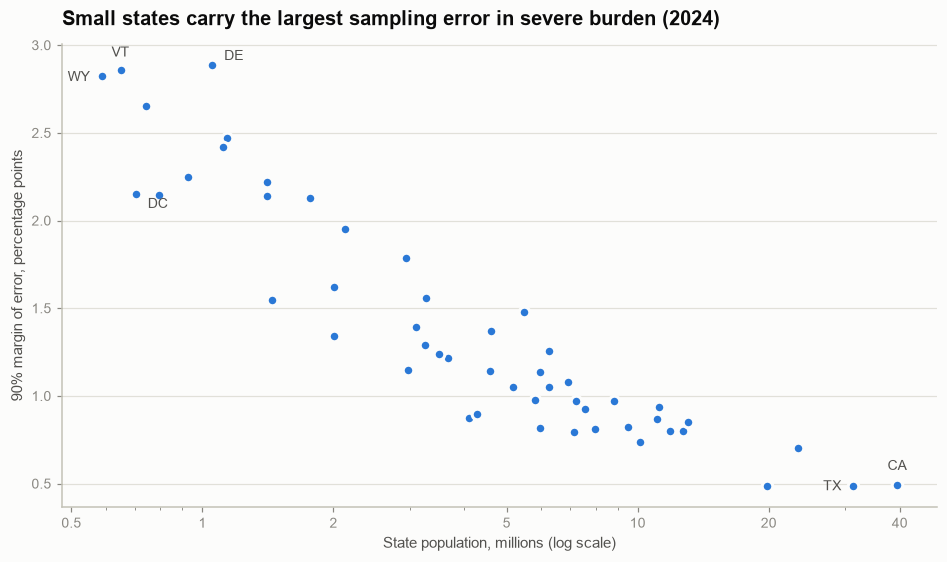

In [3]:
d24 = acs[acs.year == 2024].copy()
print(acs[MOE].describe(percentiles=[.5, .9]).round(2).to_string())

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(d24["population"] / 1e6, d24[MOE], s=48, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10, 20, 40], ["0.5", "1", "2", "5", "10", "20", "40"])
ax.set_xlabel("State population, millions (log scale)")
ax.set_ylabel("90% margin of error, percentage points")
ax.grid(axis="x", visible=False)
ax.set_title("Small states carry the largest sampling error in severe burden (2024)")
for st, dx, dy, ha in [("VT", 0, 9, "center"), ("WY", -8, -3, "right"), ("DE", 8, 3, "left"), ("CA", 0, 10, "center"),
                       ("TX", -8, -3, "right"), ("DC", 8, -9, "left")]:
    r = d24[d24.state_abbr == st].iloc[0]
    ax.annotate(st, (r.population / 1e6, r[MOE]), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=INK_2, ha=ha)
save_figure(fig, "02_margin_of_error_vs_size")
plt.show()

Table view: the ten states with the largest margins in 2024.

In [4]:
top = d24.nlargest(10, MOE)[["state_name", "population", TARGET, MOE]].rename(
    columns={"population": "population", TARGET: "severe burden, %", MOE: "90% margin, pp"})
display(top.round(2).reset_index(drop=True))

,state_name,population,"severe burden, %","90% margin, pp"
0,Delaware,1051917.0,24.19,2.89
1,Vermont,648493.0,23.58,2.86
2,Wyoming,587618.0,18.84,2.82
3,Alaska,740133.0,18.44,2.65
4,Montana,1137233.0,18.86,2.47
5,Rhode Island,1112308.0,26.19,2.42
6,South Dakota,924669.0,16.78,2.25
7,New Hampshire,1409032.0,23.24,2.22
8,District of Columbia,702250.0,25.00,2.15
9,North Dakota,796568.0,16.79,2.15


## 3. What the noise looks like in three states

Wyoming (small), Kentucky (middle), and California (large) over time. The band is the 90 percent margin of error. The
panels share one vertical scale, so the widths are comparable.

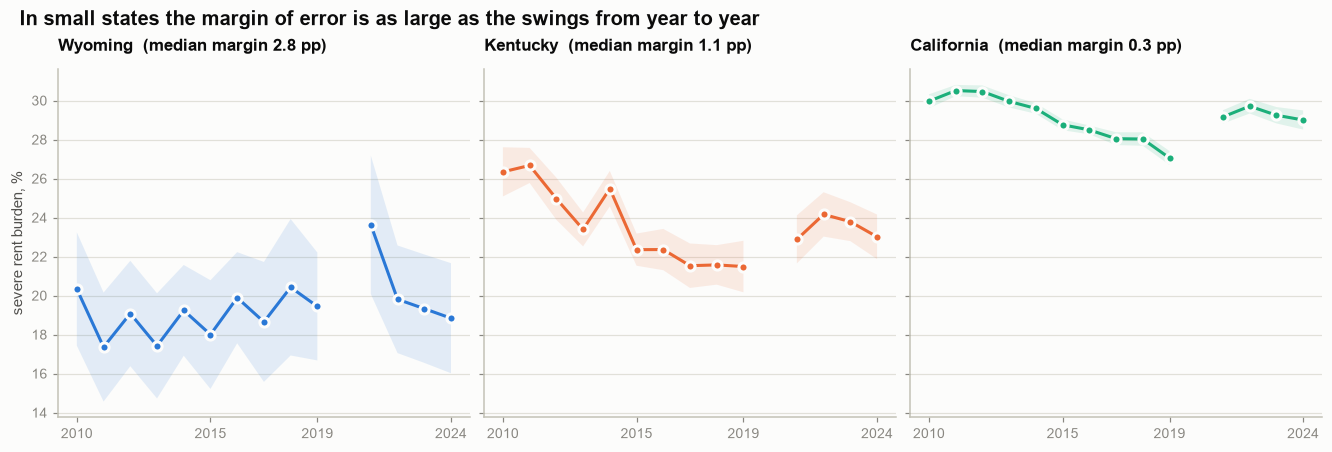

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, st, color in zip(axes, ["WY", "KY", "CA"], SERIES[:3]):
    d = acs[acs.state_abbr == st].sort_values("year")
    full = d.set_index("year").reindex(range(2010, 2025))       # 2020 stays missing so the line breaks instead of bridging it
    ax.fill_between(full.index, full[TARGET] - full[MOE], full[TARGET] + full[MOE], color=color, alpha=0.12, linewidth=0)
    ax.plot(full.index, full[TARGET], color=color)
    for _, r in d.iterrows():
        dot(ax, r.year, r[TARGET], color)
    ax.set_title(f"{d.state_name.iloc[0]}  (median margin {d[MOE].median():.1f} pp)", fontsize=11)
    ax.set_xticks([2010, 2015, 2019, 2024])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("severe rent burden, %")
fig.suptitle("In small states the margin of error is as large as the swings from year to year", x=0.01, ha="left", fontsize=13, fontweight="bold")
save_figure(fig, "02_three_states_noise_bands")
plt.show()

Table view for the same three states (selected years):

In [6]:
tab = acs[acs.state_abbr.isin(["WY", "KY", "CA"]) & acs.year.isin([2010, 2015, 2019, 2022, 2023, 2024])]
display(tab.pivot(index="year", columns="state_abbr", values=TARGET).round(1))

state_abbr,CA,KY,WY
year,,,
2010,30.0,26.3,20.3
2015,28.8,22.4,18.0
2019,27.1,21.5,19.4
2022,29.7,24.2,19.8
2023,29.2,23.8,19.3
2024,29.0,23.0,18.8


## 4. How much of the year-to-year change could noise alone produce?

For every pair of consecutive years we know the observed change and the sampling variance of that change (the sum of
the two years' variances). If sampling error were the only thing moving, the variance of observed changes would equal the
mean sampling variance.

In [7]:
def transitions(col, moe_col, relative=False):
    d = acs[["state_fips", "year", col, moe_col]].copy()
    d["se"] = d[moe_col] / Z90
    if relative:                      # percent growth: standard error as a percent of the level
        d["se"] = 100 * d["se"] / d[col]
    prev = d.assign(year=d.year + 1).rename(columns={col: "y0", "se": "se0"})[["state_fips", "year", "y0", "se0"]]
    m = d.merge(prev, on=["state_fips", "year"])
    m["change"] = 100 * (m[col] / m.y0 - 1) if relative else m[col] - m.y0
    m["noise_var"] = m.se ** 2 + m.se0 ** 2
    return m.dropna(subset=["change", "noise_var"])

series = {
    "severe rent burden (points)": ("severe_rent_burden_pct", "severe_rent_burden_pct_moe", False),
    "rent burden 30%+ (points)": ("rent_burden_30_pct", "rent_burden_30_pct_moe", False),
    "median gross rent growth (percent)": ("median_gross_rent", "median_gross_rent_moe", True),
    "median household income growth (percent)": ("median_hh_income", "median_hh_income_moe", True),
}
rows = []
for name, (col, moe, rel) in series.items():
    m = transitions(col, moe, rel)
    rows.append({"series": name, "transitions": len(m), "SD of observed change": m.change.std(), "SD from sampling error alone": np.sqrt(m.noise_var.mean()),
                 "share of change variance that is sampling error": m.noise_var.mean() / m.change.var()})
noise_tab = pd.DataFrame(rows)
display(noise_tab.round(2))

,series,transitions,SD of observed change,SD from sampling error alone,share of change variance that is sampling error
0,severe rent burden (points),612,1.38,1.20,0.76
1,rent burden 30%+ (points),612,1.76,1.55,0.78
2,median gross rent growth (percent),612,2.94,1.38,0.22
3,median household income growth (percent),612,2.52,1.53,0.37


How often does a year-to-year change fall inside the margin of error of the change itself (the two years' margins
combined in quadrature)? A change inside that margin cannot be told apart from no change.

In [8]:
mm = transitions(TARGET, MOE).merge(acs[["state_fips", "year", "state_abbr"]], on=["state_fips", "year"])
prevm = acs[["state_fips", "year", MOE]].assign(year=lambda d: d.year + 1).rename(columns={MOE: "moe0"})
mm = mm.merge(prevm, on=["state_fips", "year"])
mm["margin_of_change"] = np.sqrt(mm[MOE] ** 2 + mm.moe0 ** 2)
mm["inside"] = mm.change.abs() <= mm.margin_of_change
inside = pd.concat([mm[mm.state_abbr.isin(["WY", "KY", "CA"])].groupby("state_abbr").inside.mean().rename("three states"),], axis=1)
display(inside.round(2).T.rename_axis("share of changes inside their own margin"))
print(f"all 612 transitions: {mm.inside.mean():.0%} inside their margin; the 10 smallest states by 2024 population: "
      f"{mm[mm.state_fips.isin(acs[acs.year == 2024].nsmallest(10, 'population').state_fips)].inside.mean():.0%}")

state_abbr,CA,KY,WY
share of changes inside their own margin,,,
three states,0.5,0.67,1.0


all 612 transitions: 75% inside their margin; the 10 smallest states by 2024 population: 88%


The histogram compares the observed changes in severe burden with what sampling error alone would produce (each
transition's change redrawn from a normal with its own sampling variance, 200 times).

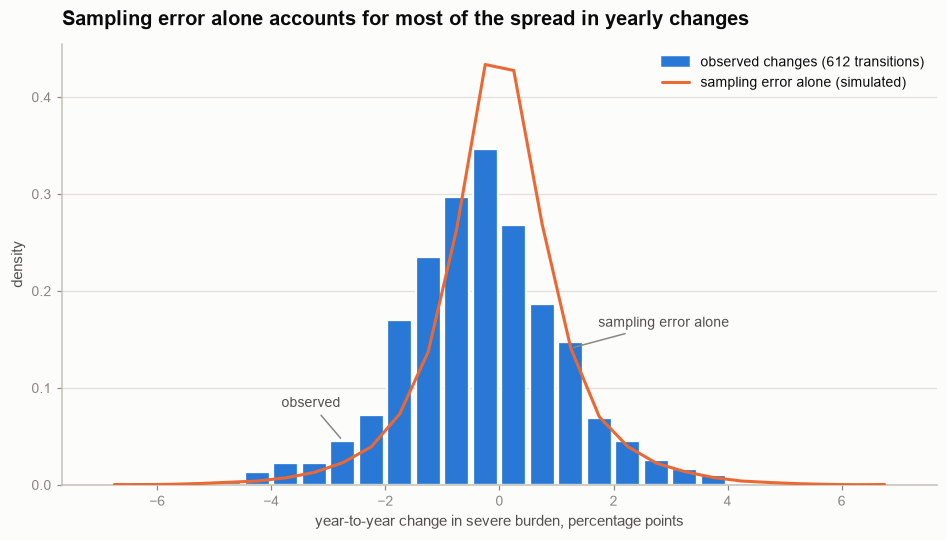

SD observed 1.38, SD of noise-only draws 1.20


In [9]:
m = transitions(TARGET, MOE)
sim = (rng.standard_normal((200, len(m))) * np.sqrt(m.noise_var.to_numpy())).ravel()
bins = np.arange(-7, 7.01, 0.5)
obs_h, _ = np.histogram(m.change.clip(-6.99, 6.99), bins=bins, density=True)
sim_h, _ = np.histogram(sim.clip(-6.99, 6.99), bins=bins, density=True)
centers = (bins[:-1] + bins[1:]) / 2

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.bar(centers, obs_h, width=0.44, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=2)
ax.plot(centers, sim_h, color=SERIES[1], zorder=3)
ax.set_xlabel("year-to-year change in severe burden, percentage points")
ax.set_ylabel("density")
ax.grid(axis="x", visible=False)
ax.set_title("Sampling error alone accounts for most of the spread in yearly changes")
ax.annotate("sampling error alone", (1.25, sim_h[np.argmin(abs(centers - 1.25))]), xytext=(18, 14), textcoords="offset points", fontsize=9, color=INK_2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.annotate("observed", (-2.75, obs_h[np.argmin(abs(centers + 2.75))]), xytext=(-40, 22), textcoords="offset points", fontsize=9, color=INK_2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SERIES[0]), plt.Line2D([0], [0], color=SERIES[1])],
          labels=["observed changes (612 transitions)", "sampling error alone (simulated)"], loc="upper right")
save_figure(fig, "02_observed_vs_noise_only_changes")
plt.show()
print(f"SD observed {m.change.std():.2f}, SD of noise-only draws {sim.std():.2f}")

## 5. Is the noise share just a small-state effect?

Transitions split into four groups by their sampling SD (smallest to largest). If the noise explanation is right, in
the noisiest group the observed SD should match the sampling SD, and in the quietest group observed movement should
exceed it (that excess is the signal).

,n,observed_sd,sampling_sd,signal_sd_if_independent
group,,,,
quietest,153,0.86,0.54,0.68
second,153,1.05,0.77,0.71
third,153,1.47,1.13,0.93
noisiest,153,1.90,1.89,0.23


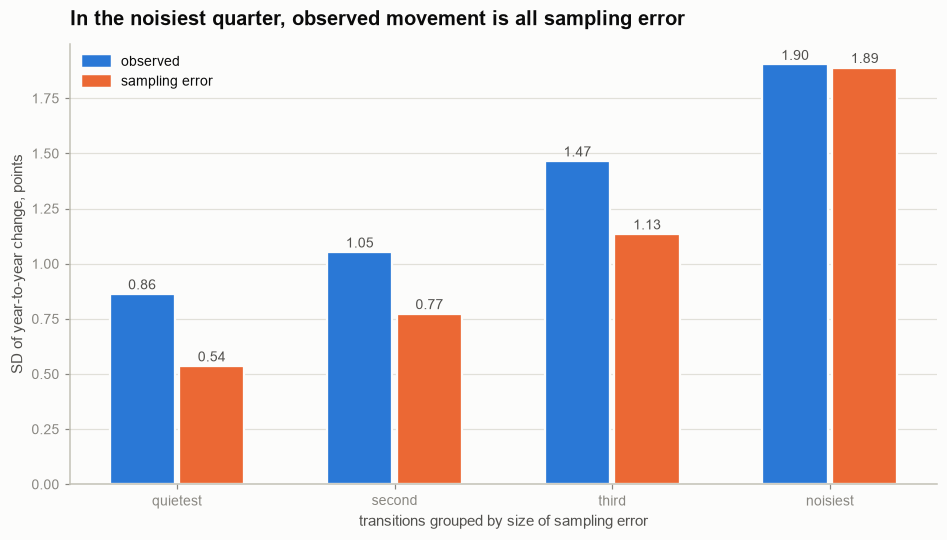

In [10]:
m["group"] = pd.qcut(m.noise_var, 4, labels=["quietest", "second", "third", "noisiest"])
g = m.groupby("group", observed=True).agg(n=("change", "size"), observed_sd=("change", "std"), sampling_sd=("noise_var", lambda v: np.sqrt(v.mean())))
g["signal_sd_if_independent"] = np.sqrt((g.observed_sd ** 2 - g.sampling_sd ** 2).clip(lower=0))
display(g.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(4)
w = 0.30
b1 = ax.bar(x - w / 2 - 0.01, g.observed_sd, width=w, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=2)
b2 = ax.bar(x + w / 2 + 0.01, g.sampling_sd, width=w, color=SERIES[1], edgecolor=SURFACE, linewidth=1.5, zorder=2)
for bars in (b1, b2):
    for r in bars:
        ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(x, g.index)
ax.set_xlabel("transitions grouped by size of sampling error")
ax.set_ylabel("SD of year-to-year change, points")
ax.grid(axis="x", visible=False)
ax.set_title("In the noisiest quarter, observed movement is all sampling error")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SERIES[0]), plt.Rectangle((0, 0), 1, 1, color=SERIES[1])],
          labels=["observed", "sampling error"], loc="upper left")
save_figure(fig, "02_noise_by_group")
plt.show()

## 6. Does a model with no dynamics reproduce the data?

Build a synthetic target that has **only** a state level and a year effect (the fitted two-way fixed effects), and add
sampling noise with each observation's own variance. If this synthetic data behaves like the real data, there is no
visible state-specific dynamics left for a forecasting model to learn beyond state and year effects. Three statistics
are compared over 500 simulated panels: the SD of year-to-year changes, the autocorrelation of consecutive changes, and
the error of the persistence forecast (next year equals this year).

In [11]:
y = acs.pivot(index="state_fips", columns="year", values=TARGET)
se = acs.pivot(index="state_fips", columns="year", values="se")
fit = y.mean(axis=1).values[:, None] + y.mean(axis=0).values[None, :] - y.stack().mean()
years = list(y.columns)
consec = [(a, b) for a, b in zip(years[:-1], years[1:]) if b - a == 1]

def stats_for(values):
    v = pd.DataFrame(values, index=y.index, columns=years)
    ch = {b: v[b] - v[a] for a, b in consec}
    allch = pd.concat(ch.values())
    pairs = [(ch[b1], ch[b2]) for (a1, b1), (a2, b2) in zip(consec[:-1], consec[1:]) if b1 + 1 == b2]
    ac = np.nanmean([x.corr(z) for x, z in pairs])
    return allch.std(), ac, allch.abs().mean()

obs = stats_for(y.values)
sims = np.array([stats_for(fit + rng.standard_normal(fit.shape) * se.values) for _ in range(500)])
cmp = pd.DataFrame({"observed": obs, "simulated mean": sims.mean(axis=0), "simulated 5th pct": np.percentile(sims, 5, axis=0),
                    "simulated 95th pct": np.percentile(sims, 95, axis=0)},
                   index=["SD of 1-year change", "autocorrelation of changes", "persistence forecast error (MAE)"])
display(cmp.round(3))
inside = ((cmp["observed"] >= cmp["simulated 5th pct"]) & (cmp["observed"] <= cmp["simulated 95th pct"])).to_dict()
print("observed inside the simulated 5th to 95th percentile range:", inside)

,observed,simulated mean,simulated 5th pct,simulated 95th pct
SD of 1-year change,1.378,1.284,1.194,1.372
autocorrelation of changes,-0.350,-0.489,-0.556,-0.417
persistence forecast error (MAE),1.088,0.990,0.932,1.046


observed inside the simulated 5th to 95th percentile range: {'SD of 1-year change': False, 'autocorrelation of changes': False, 'persistence forecast error (MAE)': False}


## 7. The floor that sampling error sets on any forecast

Suppose a forecaster knew each state's true severe burden exactly. The next published value would still differ from it
by that year's sampling error, so even this oracle has a forecast error floor. Compare the floor with the persistence
forecast, which is what every model must beat.

In [12]:
floor_mae = float(np.mean(np.sqrt(2 / np.pi) * acs.se))
persist_mae = float(np.nanmean(np.abs(transitions(TARGET, MOE).change)))
print(f"oracle floor (mean absolute error from sampling error alone): {floor_mae:.2f} points")
print(f"persistence forecast, 1 year ahead (mean absolute change):    {persist_mae:.2f} points")
print(f"largest possible improvement over persistence: {100 * (1 - floor_mae / persist_mae):.0f} percent, and only for an oracle")

oracle floor (mean absolute error from sampling error alone): 0.61 points
persistence forecast, 1 year ahead (mean absolute change):    1.09 points
largest possible improvement over persistence: 44 percent, and only for an oracle


## Findings

1. **The variation is mostly between states.** For severe burden, 73.5 percent of the variance is differences between
   state levels, 12.0 percent is year effects common to all states, and only 14.4 percent is left for state-specific
   movement plus sampling error. Rent is different: 35.4 percent is common year effects (national rent inflation) and only
   5.1 percent is left.
2. **Sampling error is large and depends on size.** The median 90 percent margin of error on severe burden is 1.07 points
   (90th percentile 2.22, maximum 3.55). Delaware, Vermont, and Wyoming are near 2.8 to 2.9 points; California and Texas
   are near 0.5.
3. **Most year-to-year changes cannot be told from no change.** 75 percent of the 612 changes fall inside their own
   margin of error, and 88 percent in the ten smallest states.
4. **Sampling error explains most of the variance of changes in the burden rates, but not of rent growth.** Share of the
   variance of year-to-year changes that sampling error alone accounts for: severe burden 76 percent, 30-percent
   burden 78 percent, median household income growth 37 percent, median gross rent growth only 22 percent. Rent growth
   carries real signal; the burden rates mostly carry noise.
5. **The pattern follows the size of the noise.** In the quarter of transitions with the largest sampling error the observed
   SD of changes (1.90) equals the sampling SD (1.89), so there is no visible signal there. In the quietest quarter the
   observed SD (0.86) exceeds the sampling SD (0.54), which implies a true-change SD of about 0.7 points.
6. **There is some real state-specific movement beyond state and year effects, but not much.** A synthetic series with only
   state and year effects plus sampling noise lands close to the data but outside it on all three statistics: SD of
   changes 1.38 observed against 1.28 simulated (5th to 95th percentile 1.19 to 1.37), autocorrelation of changes -0.35
   against -0.49 (-0.56 to -0.42), persistence error 1.09 against 0.99 (0.93 to 1.05).
7. **The ceiling is low.** An oracle that knew every state's true burden would still miss the next published value by
   0.61 points on average, against 1.09 for the persistence forecast, so even a perfect model could improve on
   persistence by 44 percent at most, and no real model will come close.

**What this means for the modeling plan**

* Judge every model against persistence and against this floor. A few percent over persistence is a real result at this
  noise level, and with 6 to 9 test origins it will often not be statistically distinguishable, so report win rates
  across origins as well as the Diebold-Mariano test.
* Model the measurement error explicitly. The hierarchical Bayesian model in Part 2 should take each state-year's
  sampling variance as known (we have it) and forecast the true burden, shrinking noisy small states toward their own
  history and the national pattern.
* Do not rank states on a single year of severe burden, and do not read a one-year change in a small state as a trend.
  The need index should use multi-year smoothing or model-based estimates and report uncertainty, with CHAS as a
  cross-check.
* Rent growth and income growth are where predictors have something to find, so that is where the machine learning
  bake-off has the most room.

**Caveats.** The published margins are taken as accurate, and consecutive years' samples as independent. In the noisiest
quarter, observed equal to sampling could also mean the margins are slightly overstated there, which this analysis cannot
separate from small states genuinely changing little.